<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# Atlantic swell into the Bay of Biscay 🌊
### ECMWF open data · wave model · the latest forecast · no account needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/france/swell_forecast.ipynb)

ECMWF's wave model forecasts the sea state worldwide, and it is **open data**: no login, no fee. This
notebook takes the latest six-day forecast of **significant wave height** (roughly the height of the biggest third of the
waves) and the **peak wave period**, finds the moment the biggest waves reach the French Atlantic coast, and maps it with
arrows showing where the waves are heading. Long periods (14 s and more) mean swell, made by storms far out in the Atlantic.

**What you need:** a Google account (to use Colab). No other account, no fee, nothing to install. Everything runs on Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| [ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data), wave model (0.25°) | significant wave height, mean direction, peak period; latest 00 UTC run, 6-hourly to +144 h | CC BY 4.0, © ECMWF |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data.

*Press **Runtime → Run all**. The first run takes a few minutes, mostly installing the tools.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to France (Météo-France, Toulouse), 2026. The visit graphic shows the run of 18 November 2026; this notebook always shows the newest run.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots

In [2]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the area

In [3]:
AREA  = [52.0, -20.0, 42.0, 0.0]          # north, west, south, east: Bay of Biscay and the approaches
COAST = [48.8, -6.0, 43.3, -1.0]           # the French Atlantic coast box used to find the stormiest moment
STEPS = list(range(0, 145, 6))             # every 6 hours, six days ahead
PLACES = [("Brest", 48.390, -4.486), ("Saint-Nazaire", 47.274, -2.214), ("La Rochelle", 46.160, -1.151),
          ("Arcachon", 44.661, -1.168), ("Biarritz", 43.483, -1.559)]

def label_places(chart, places):
    for name, la, lo in places:
        chart.scatter(x=[lo], y=[la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10)
        chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                      color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get the wave forecast (ECMWF open data)

In [4]:
fc = ekd.from_source("ecmwf-open-data", stream="wave", type="fc", param=["swh", "mwd", "pp1d"], step=STEPS)
ds = fc.to_xarray()
ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude").sortby("latitude")
ds = ds.sel(latitude=slice(AREA[2], AREA[0]), longitude=slice(AREA[1], AREA[3]))
sdim = [d for d in ds.swh.dims if d not in ("latitude", "longitude")][0]
coast = ds.swh.sel(latitude=slice(COAST[2], COAST[0]), longitude=slice(COAST[1], COAST[3]))
storm = int(coast.mean(["latitude", "longitude"]).argmax())         # the stormiest moment off the French coast
swh, mwd, tp = (ds[v].isel({sdim: storm}) for v in ("swh", "mwd", "pp1d"))
md0 = fc.to_fieldlist()[0].metadata
run = dt.datetime.strptime(f"{md0('dataDate')}{int(md0('dataTime')):04d}", "%Y%m%d%H%M")     # run time from the GRIB header
valid = run + dt.timedelta(hours=STEPS[storm])
c = coast.isel({sdim: storm})
print(f"Forecast from {run:%d %B %Y %H} UTC. Stormiest off the French coast: {valid:%A %d %B %H}:00 UTC (+{STEPS[storm]} h), "
      f"waves {float(c.mean()):.1f} m on average there, up to {float(c.max()):.1f} m; "
      f"peak period {float(tp.sel(latitude=slice(COAST[2], COAST[0]), longitude=slice(COAST[1], COAST[3])).mean()):.0f} s")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Forecast from 23 November 2026 00 UTC. Stormiest off the French coast: Wednesday 25 November 18:00 UTC (+66 h), waves 3.9 m on average there, up to 5.6 m; peak period 11 s


## 3 · Map it

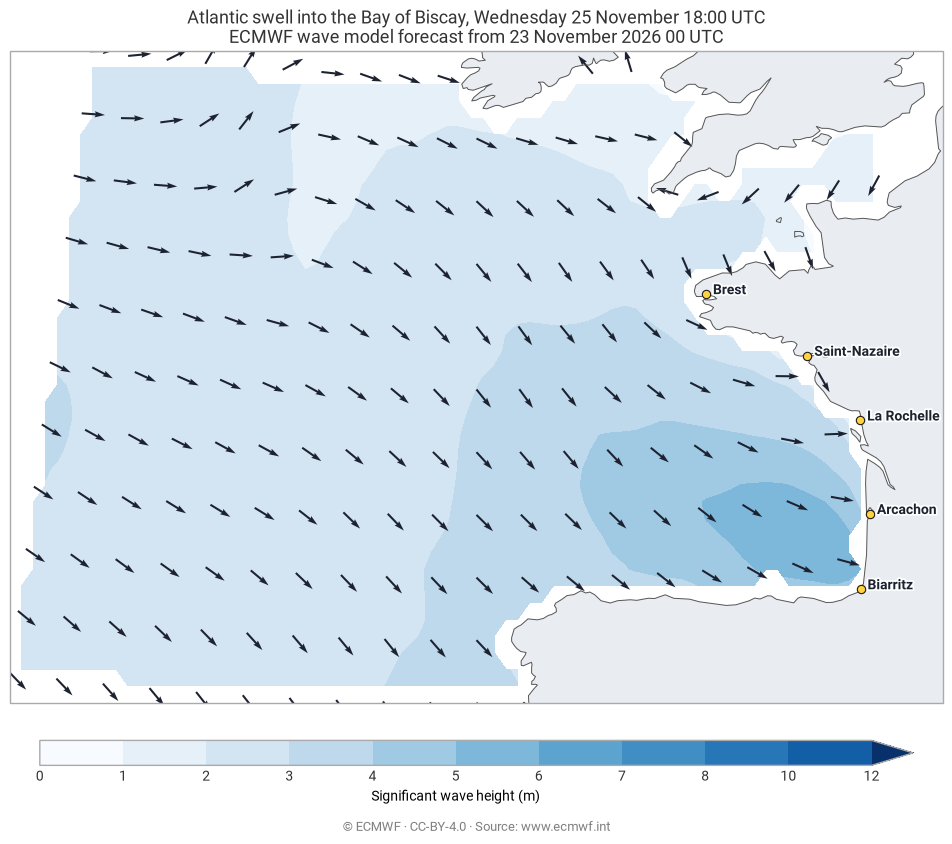

In [5]:
style = ekp.styles.Style(levels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 12], colors="Blues", extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(11, 8))
chart.contourf(swh, style=style)
chart.land(color="#e9ecf1"); chart.coastlines(linewidth=0.7)
# arrows point where the waves are going (mwd is the direction they come from)
th = np.radians(mwd.values[::4, ::4]); lo, la = np.meshgrid(mwd.longitude.values[::4], mwd.latitude.values[::4])
chart.ax.quiver(lo, la, -np.sin(th), -np.cos(th), transform=ccrs.PlateCarree(), color="#1d2230", scale=40, width=0.0022)
label_places(chart, PLACES)
chart.legend(label="Significant wave height (m)")
chart.title(f"Atlantic swell into the Bay of Biscay, {valid:%A %d %B %H}:00 UTC\n"
            f"ECMWF wave model forecast from {run:%d %B %Y %H} UTC", fontsize=13)
chart.attribution("© ECMWF · CC-BY-4.0 · Source: www.ecmwf.int")
chart.save("swell_forecast.png")
chart.show()

## 4 · Your turn 🌍

- **A different moment:** set `storm = 0` (now) or any index into `STEPS`, then re-run steps 2 and 3.
- **Swell, not wind sea:** map `tp` (peak period, seconds) instead of `swh`: 12 s and longer is ocean swell.
- **Anywhere else:** change `AREA` and `COAST`, for example `[44.5, 2.0, 40.5, 10.0]` for the Gulf of Lion.
- **A past run:** add `source="aws", date="2026-11-18"` to the request (the AWS mirror keeps older runs).

### Data & licence
ECMWF Open Data is free under **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. No account, no key.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [earthkit](https://earthkit.ecmwf.int)